# 3 T-junctions, geometry matched to the TensorBinding array

Same MSH model as V5 (`build_system`: $-\mu\tau_z + \Delta\tau_x$ on every site, $J\,\mathbf S\cdot\boldsymbol\sigma$ on chain sites,
`hop_x` $= -t\tau_z + i\alpha\tau_z\sigma_y$, `hop_y` $= -t\tau_z - i\alpha\tau_z\sigma_x$, basis $(c_\uparrow, c_\downarrow, c^\dagger_\downarrow, -c^\dagger_\uparrow)$),
but with the geometry and protocols of the Julia/TensorBinding array (`msh_tjunction_gates.ipynb`),
so the two can be compared number for number.

Changes from V5:
* **3 T-junctions** instead of 7 vertical legs; junction sites at $x_c = -32, 0, 32$ (spacing 32, V5: 30).
* **Horizontal chain** $y=0$, $x = -48\dots47$; each cell has 16 sites left of the junction ($x_c-16\dots x_c-1$) and 16 from the junction to the right ($x_c\dots x_c+15$).
* **Vertical legs** $x = x_c$, $y = 1\dots16$ (16 sites, V5: 14), pointing up; no extra non-magnetic site on top (V5 keeps one at the top of each leg).
* No substrate (same as V5, where `d = 0` with `cutouts=True` deletes every substrate site).
* Spin texture as in the Julia code: $\mathbf S = (\cos\phi\sin\theta, \sin\phi\sin\theta, \cos\theta)$, $\theta = (-1)^{x+y}\,\tfrac{\pi}{2} f$,
  $\phi = \theta_{\rm arm} + \pi/2$ with arm angles $0$ (right), $\pi$ (left), $\pi/2$ (up). (V5 uses $\phi=\pi/2$ on the whole horizontal chain and $\phi = 0$ on the legs.)
  $f = 0$: $\mathbf S\parallel\hat z$ (topological), $f = 1$: in-plane AFM (trivial).
* Protocols: V5's `exchange_12` (Z gate when applied twice), `exchange_23` (X gate when applied twice) and `fuse_56` (partial fusion),
  written for $L_1 = L_2 = 14$ and mapped onto the 16-site legs exactly as in the Julia code.

Analysis (same as the Julia runs): evolve the two $+E$ modes $\psi_A = (\gamma_1 + i\gamma_2)/\sqrt2$, $\psi_B = (\gamma_3 + i\gamma_4)/\sqrt2$;
braid matrix $M_{ij} = \langle\gamma_i(0)|\gamma_j(T)\rangle$; logical gate = spin representation of $M$ on $|0\rangle_L = |00\rangle$, $|1\rangle_L = |11\rangle$;
fusion readout $\Delta Q = Q(U|1\rangle) - Q(U|0\rangle) = \sum_{k=A,B}\langle\psi_k|\tau_z|\psi_k\rangle$.

Additional outputs (merged from `ldos_charge_density_kwant.ipynb`):
* **Subgap LDOS** (after the Hamiltonian): full diagonalization of $H(f_0)$, total (particle + hole, spin-summed) LDOS
  with Gaussian broadening $\eta = 0.01$; zero-energy LDOS map on the lattice with the initial spin texture.
* **Charge density** $\delta n(x, t) = n_1 - n_0$ along the horizontal chain (last section), taken from snapshots of the
  same Z and X + fusion evolutions used for the gate analysis (every 5 time units during the gate, every 1 during
  the fusion), so no extra time evolution is needed.

Figures and `.npz` data are written to `DATA_DIR`.

In [1]:
import os
os.environ.setdefault("OMP_NUM_THREADS", "1")          # tiny matrices: threaded BLAS only adds contention
os.environ.setdefault("OPENBLAS_NUM_THREADS", "1")
os.environ.setdefault("MKL_NUM_THREADS", "1")
import matplotlib.pyplot as plt
import numpy as np
import kwant
from scipy import linalg as la
from tqdm import trange
import time

plt.rcParams["figure.dpi"] = 144
plt.rcParams["font.size"] = 12

DATA_DIR = "3_tjunctions_kwant_data"     # LDOS / δn figures and .npz
os.makedirs(DATA_DIR, exist_ok=True)

In [2]:
#pauli matrices
tau_0 = np.array([[1, 0], [0, 1]])
tau_x = np.array([[0, 1], [1, 0]])
tau_y = np.array([[0, -1j], [1j, 0]])
tau_z = np.array([[1, 0], [0, -1]])

#tensor products; used in Hamiltonian function
txs0 = np.kron(tau_x, tau_0)
t0sx = np.kron(tau_0, tau_x)
t0sy = np.kron(tau_0, tau_y)
t0sz = np.kron(tau_0, tau_z)
tzsx = np.kron(tau_z, tau_x)
tzsy = np.kron(tau_z, tau_y)
tzs0 = np.kron(tau_z, tau_0)
tysy = np.kron(tau_y, tau_y)

## Geometry

`label[(x, y)] = (c, s, n)`: cell $c = 1, 2, 3$, arm $s$ (1 right, 2 left, 3 up), position $n = 0\dots15$ along the arm
(arm 1 starts at the junction site, arm 2 at $x_c - 1$, arm 3 at $y = 1$), the same labels as the Julia `TArray`.

144 sites; x = -48 … 47 ; legs at x = [-32, 0, 32]


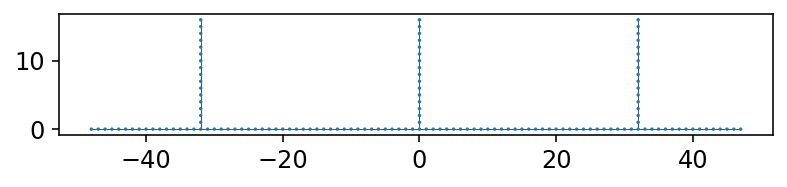

In [3]:
NLEG = 16        # sites per arm (Julia TArray L = 4)
NCELL = 3
SPACING = 2 * NLEG
ARM_ANG = (0.0, np.pi, np.pi / 2)              # right, left, up
ARM_ORIG = ((0, 0), (-1, 0), (0, 1))
ARM_DIR = ((1, 0), (-1, 0), (0, 1))

def center_x(c):
    return int((c - (NCELL + 1) / 2) * SPACING)

def array_pos(c, s, n):
    return (center_x(c) + ARM_ORIG[s-1][0] + n * ARM_DIR[s-1][0],
            ARM_ORIG[s-1][1] + n * ARM_DIR[s-1][1])

label = {array_pos(c, s, n): (c, s, n) for c in range(1, NCELL + 1) for s in (1, 2, 3) for n in range(NLEG)}

def build_system_3T():
    # all sites are chain sites; kwant adds hoppings only between sites that exist
    def chain(site, mu, Delta, J, S):
        Sx, Sy, Sz = S[site.tag]
        JS = J * (Sx * t0sx + Sy * t0sy + Sz * t0sz)
        return -mu * tzs0 + Delta * txs0 + JS

    def hop_x(sitei, sitej, t, alpha):
        return -t * tzs0 + 1j * alpha * tzsy

    def hop_y(sitei, sitej, t, alpha):
        return -t * tzs0 - 1j * alpha * tzsx

    sys = kwant.Builder()
    lat = kwant.lattice.square(norbs=4)
    for (x, y) in label:
        sys[lat(x, y)] = chain
    for delta, hop in zip([(1, 0), (0, 1)], [hop_x, hop_y]):
        sys[kwant.HoppingKind(delta, lat)] = hop
    return sys.finalized()

sys = build_system_3T()
N = len(sys.sites)
tags = [tuple(int(v) for v in site.tag) for site in sys.sites]
xs = np.array([p[0] for p in tags]); ys = np.array([p[1] for p in tags])
print(N, "sites; x =", xs.min(), "…", xs.max(), "; legs at x =", [center_x(c) for c in range(1, NCELL + 1)])
kwant.plot(sys);

## Spin texture and protocols (ported from the Julia code)

`f(c, s, n)` is the rotation fraction (0 topological, 1 trivial). The initial setup has cells 1 and 3 horizontal topological,
cell 2 and every vertical leg trivial, giving 4 MZMs: $\gamma_1,\gamma_2$ at the ends of cell 1's segment, $\gamma_3,\gamma_4$ at cell 3's.

In [4]:
def smoothstep(t):
    return 0.0 if t <= 0 else 1.0 if t >= 1 else np.sin(0.5 * np.pi * t) ** 2

f0 = lambda c, s, n: 1.0 if (c == 2 or s == 3) else 0.0

def spins(f):
    # S[(x, y)] for the texture f(c, s, n);  θ = (−1)^(x+y) (π/2) f,  φ = θ_arm + π/2
    S = {}
    for (x, y), (c, s, n) in label.items():
        th = (-1) ** (x + y) * (np.pi / 2) * f(c, s, n)
        ph = ARM_ANG[s-1] + np.pi / 2
        S[(x, y)] = (np.cos(ph) * np.sin(th), np.sin(ph) * np.sin(th), np.cos(th))
    return S

# ── exchange_12 (V5, L1 = L2 = 14, rot_Tz = 200, step_Tz = 0.1) on cell 1 ──
class Exchange12:
    def __init__(self, L1=14, L2=14, rot_T=200.0, step_T=0.1):
        self.L1, self.L2, self.rot_T, self.step_T = L1, L2, rot_T, step_T
    def duration(self):
        return (self.step_T * (4 * self.L1 + 2 * self.L2 + 8) + 1) * self.rot_T

def f_horizontal_12(p, i, t):
    tau, s, L1, L2 = t / p.rot_T, p.step_T, p.L1, p.L2
    ss = smoothstep
    if 0 <= i <= L1:
        return ss(tau - s * (i + L1 + L2 + 2)) - ss(tau - s * (L1 - i + 3 * L1 + 2 * L2 + 8))
    if i == L1 + 1:
        return 0.0
    if L1 + 2 <= i <= 2 * L1 + 2:
        return ss(tau - s * (2 * L1 + 2 - i)) - ss(tau - s * (i + L1 + L2 + 2))
    return 1.0

def f_vertical_12(p, k, t):
    tau, s, L1, L2 = t / p.rot_T, p.step_T, p.L1, p.L2
    ss = smoothstep
    return 1 - ss(tau - s * (k + L1 + 2)) + ss(tau - s * (L2 - k + 3 * L1 + L2 + 5))

def f_braid_12(p, t):
    # arm 1: i = L1 + 1 + n;  arm 2: i = max(L1 − n, 0);  arm 3: k = min(n, L2)
    return lambda s, n: (f_horizontal_12(p, p.L1 + 1 + n, t) if s == 1 else
                         f_horizontal_12(p, max(p.L1 - n, 0), t) if s == 2 else
                         f_vertical_12(p, min(n, p.L2), t))

def f_array_12(p, t):
    fb = f_braid_12(p, t)
    return lambda c, s, n: fb(s, n) if c == 1 else f0(c, s, n)

# ── exchange_23 (V5, rot_Tx = 100, step_Tx = 0.1) through cell 2 ──
class Exchange23:
    def __init__(self, L1=14, L2=14, rot_T=100.0, step_T=0.1):
        self.L1, self.L2, self.rot_T, self.step_T = L1, L2, rot_T, step_T
    def duration(self):
        return (self.step_T * (self.L1 + 3 * self.L2 + 2 * self.L1 + 3) + 1) * self.rot_T

def f_h23(p, i, t):
    tau, s, L1, L2 = t / p.rot_T, p.step_T, p.L1, p.L2
    ss = smoothstep
    if 2 * L1 + 3 <= i <= 3 * L1 + 3:
        return 1 - ss(tau - s * (i - 2 * L1 - 3)) + ss(tau - s * (4 * L1 + 4 - i + L2 + L1 + 2))
    if 3 * L1 + 4 <= i <= 4 * L1 + 4:
        return 1 - ss(tau - s * (4 * L1 + 4 - i + L2 + L1 + 1)) + ss(tau - s * (i - 3 * L1 - 4 + 3 * L2 + 2 * L1 + 3))
    raise ValueError(f"i = {i} outside junction 2's segment")

def f_v23(p, k, t):
    tau, s = t / p.rot_T, p.step_T
    ss = smoothstep
    return 1 - ss(tau - s * (k + p.L1 + 2)) + ss(tau - s * (p.L2 - k + 3 * p.L1 + p.L2 + 5))

def f_array_23(p, t):
    # cell 2: right arm i = 3L1 + 3 + n; left arm (16 sites) mapped linearly onto i = 3L1 + 2 … 2L1 + 3; up k = min(n, L2)
    def f(c, s, n):
        if c != 2:
            return f0(c, s, n)
        if s == 1:
            return f_h23(p, 3 * p.L1 + 3 + n, t)
        if s == 2:
            return f_h23(p, (3 * p.L1 + 2) - (p.L1 - 1) * n / (p.L1 + 1), t)
        return f_v23(p, min(n, p.L2), t)
    return f

# ── fuse_56-style partial fusion of pair A on cell 1 (rot_T0 = 100, step_T0 = 0.2, Lp = 1) ──
class Fusion:
    def __init__(self, L1=14, Lp=1, rot_T=100.0, step_T=0.2):
        self.L1, self.Lp, self.rot_T, self.step_T = L1, Lp, rot_T, step_T
    def duration(self):
        return ((self.L1 - self.Lp + 1) * self.step_T + 1) * self.rot_T

def f_fuse(q, t):
    tau = t / q.rot_T
    def f(c, s, n):
        if c != 1:
            return f0(c, s, n)
        if s == 3:
            return 1.0
        if s == 2 and n < q.Lp:
            return 0.0
        if s == 1 and n <= q.Lp:
            return 0.0
        return smoothstep(tau - q.step_T * (NLEG - 1 - n))     # outer end first
    return f

## Hamiltonian

`ham_kwant(f)` is the full kwant matrix. For time evolution, $H(t) = H_{J=0} + J\sum_{\rm chain}\tau_0\otimes\mathbf S\cdot\boldsymbol\sigma$
is assembled from the $J = 0$ kwant matrix and the exchange blocks, which is identical and much faster (checked below).

In [5]:
params = dict(t=1.0, mu=-7.0, alpha=0.9, Delta=2.4, J=5.8)

def ham_kwant(f, **kw):
    p = {**params, **kw, "S": spins(f)}
    return sys.hamiltonian_submatrix(params=p)

H_noJ = ham_kwant(f0, J=0.0)

def exchange_matrix(f, J=params["J"]):
    S = spins(f)
    H = np.zeros((4 * N, 4 * N), complex)
    for k, p in enumerate(tags):
        Sx, Sy, Sz = S[p]
        H[4*k:4*k+4, 4*k:4*k+4] = J * (Sx * t0sx + Sy * t0sy + Sz * t0sz)
    return H

def ham(f):
    return H_noJ + exchange_matrix(f)

def Cop(v):
    # particle–hole conjugation in the (u↑, u↓, v↓, −v↑) basis:  C = τ_y σ_y K  (C H* C = −H)
    return (np.kron(np.eye(N), tysy) @ v.conj())

H0 = ham(f0)
print("‖H_fast − H_kwant‖ =", la.norm(H0 - ham_kwant(f0)),
      "  Hermitian:", la.norm(H0 - H0.conj().T),
      "  PH: ‖C H* C + H‖ =", la.norm(np.kron(np.eye(N), tysy) @ H0.conj() @ np.kron(np.eye(N), tysy) + H0))

‖H_fast − H_kwant‖ = 0.0   Hermitian: 0.0   PH: ‖C H* C + H‖ = 0.0


## Check against the Julia/TensorBinding array

`tb_reference/*.bin` are dense BdG matrices written by `export_tb_reference` in `msh_tjunction_gates.ipynb` (section 8) (basis $(c_\uparrow, c_\downarrow, c^\dagger_\uparrow, c^\dagger_\downarrow)$,
order nambu ⊗ spin ⊗ site, sites listed in `coords.txt`). Per site, the Julia basis is $W$ times the kwant one:
$(u_\uparrow, u_\downarrow, v_\uparrow, v_\downarrow) = (a, b, -d, c)$ for kwant components $(a, b, c, d) = (u_\uparrow, u_\downarrow, v_\downarrow, -v_\uparrow)$.

In [6]:
ref_dir = "tb_reference"
coords = [tuple(map(int, l.split())) for l in open(os.path.join(ref_dir, "coords.txt"))]
Wsite = np.array([[1, 0, 0, 0], [0, 1, 0, 0], [0, 0, 0, -1], [0, 0, 1, 0]])
kpos = {p: k for k, p in enumerate(tags)}
P = np.zeros((4 * N, 4 * N))            # kwant (site-major) → Julia (nambu ⊗ spin ⊗ site)
for j, p in enumerate(coords):
    k = kpos[p]
    for b in range(4):                  # Julia component b = (nambu, spin)
        for a in range(4):
            P[b * N + j, 4 * k + a] = Wsite[b, a]

def to_tb_basis(H):
    return P @ H @ P.T

checks = {"initial": f0,
          "z_t1020": f_array_12(Exchange12(), 1020.0),
          "x100_t485": f_array_23(Exchange23(rot_T=100.0), 485.0),
          "fuse_t300": f_fuse(Fusion(), 300.0)}
for name, f in checks.items():
    Href = np.fromfile(os.path.join(ref_dir, name + ".bin"), dtype=np.complex128).reshape(4 * N, 4 * N, order="F")
    print(f"{name:10s}  ‖H_kwant − H_TensorBinding‖ = {la.norm(to_tb_basis(ham_kwant(f)) - Href):.1e}")

initial     ‖H_kwant − H_TensorBinding‖ = 6.0e-16
z_t1020     ‖H_kwant − H_TensorBinding‖ = 6.0e-16


x100_t485   ‖H_kwant − H_TensorBinding‖ = 6.0e-16
fuse_t300   ‖H_kwant − H_TensorBinding‖ = 6.0e-16


## Subgap LDOS and zero-energy map with spins

$A(\mathbf r, \omega) = \sum_k w_k(\mathbf r)\, g_\eta(\omega - E_k)$, where $w_k$ sums $|U|^2$ over the four orbitals of
each site and $g_\eta$ is a Gaussian with $\eta = 0.01$, on $\omega \in [-0.2, 0.2]$ (401 points). All eigenstates are
included: those at $|E| \ge 0.268$ contribute less than $e^{-23}$ inside the window.
Spins are drawn as in V5: in-plane $(S_x, S_y)$ arrows and $\hat z$ spins as dots.

lowest |E| (one per ± pair): [0.     0.     0.127  0.2683] ; max A(r, 0) = 15.21


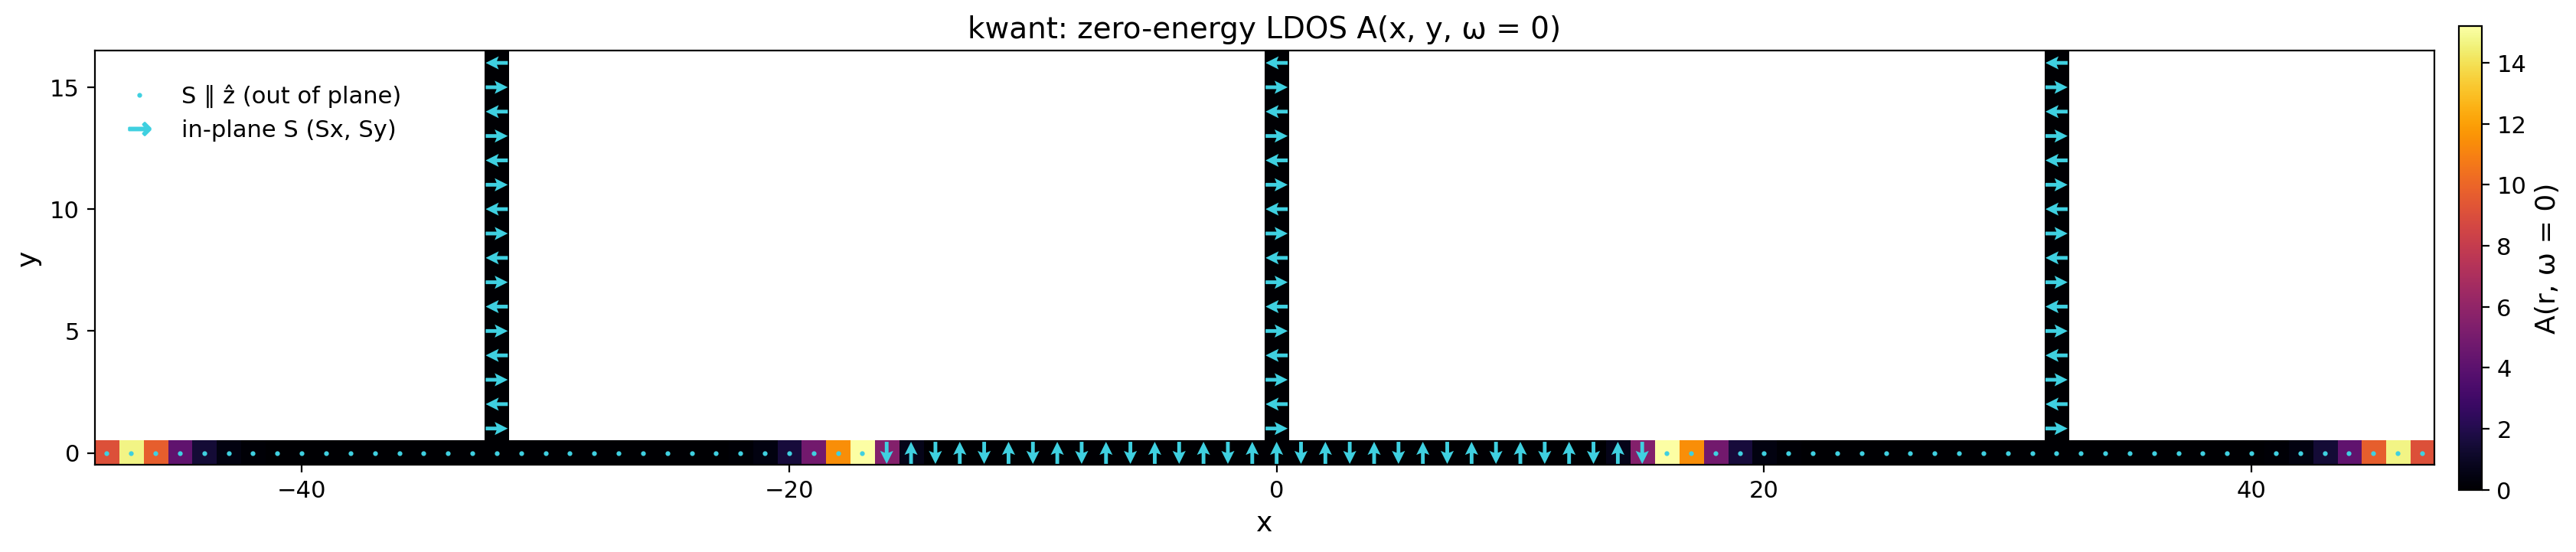

In [7]:
eta = 0.01
omega = np.linspace(-0.2, 0.2, 401)
E_all, U_all = la.eigh(H0)
w_site = (np.abs(U_all) ** 2).reshape(N, 4, -1).sum(axis=1)                    # (site, state)
g_eta = np.exp(-(omega[None, :] - E_all[:, None]) ** 2 / (2 * eta ** 2)) / (np.sqrt(2 * np.pi) * eta)
A_ldos = w_site @ g_eta                                                          # (site, ω)
j0 = np.argmin(np.abs(omega))
print("lowest |E| (one per ± pair):", np.round(np.sort(np.abs(E_all))[:8:2], 4),
      "; max A(r, 0) =", round(A_ldos[:, j0].max(), 2))

S0 = spins(f0); Sx0, Sy0, Sz0 = (np.array([S0[p][k] for p in tags]) for k in range(3))

def ldos_figure(Amat, name, out, vmax):
    x0, y0 = xs.min(), ys.min()
    grid = np.full((ys.max() - y0 + 1, xs.max() - x0 + 1), np.nan)
    grid[ys - y0, xs - x0] = Amat[:, j0]
    fig, ax = plt.subplots(figsize=(17.04, 3.6), dpi=200)
    im = ax.imshow(np.ma.masked_invalid(grid), origin="lower", cmap="inferno", vmin=0, vmax=vmax,
                   extent=(x0 - 0.5, xs.max() + 0.5, y0 - 0.5, ys.max() + 0.5), interpolation="nearest")
    ax.set_facecolor("white")
    inpl = np.hypot(Sx0, Sy0) > 0.5
    ax.quiver(xs[inpl], ys[inpl], Sx0[inpl], Sy0[inpl], color="#3FD0E0", angles="xy", scale_units="xy", scale=1.1,
              pivot="mid", width=0.0016, headwidth=3.5, headlength=3.5, headaxislength=3)
    ax.plot(xs[~inpl], ys[~inpl], ".", color="#3FD0E0", ms=2.5, label="S ∥ ẑ (out of plane)")
    ax.plot([], [], marker=r"$\rightarrow$", ls="", color="#3FD0E0", ms=10, label="in-plane S (Sx, Sy)")
    ax.legend(loc="upper left", bbox_to_anchor=(0.0, 0.97), fontsize=11, frameon=False)
    ax.set(xlabel="x", ylabel="y", title=f"{name}: zero-energy LDOS A(x, y, ω = 0)")
    ax.set_aspect("equal"); ax.set_yticks([0, 5, 10, 15])
    cb = fig.colorbar(im, ax=ax, fraction=0.025, pad=0.01); cb.set_label("A(r, ω = 0)", size=13)
    cb.ax.tick_params(labelsize=11)
    ax.title.set_size(14); ax.xaxis.label.set_size(13); ax.yaxis.label.set_size(13); ax.tick_params(labelsize=11)
    fig.tight_layout(); fig.savefig(out, bbox_inches="tight"); plt.show(); plt.close(fig)

np.savez(os.path.join(DATA_DIR, "array_ldos_kwant.npz"), x=xs, y=ys, omega=omega, A=A_ldos)
ldos_figure(A_ldos, "kwant", os.path.join(DATA_DIR, "array_ldos_kwant.png"), A_ldos[:, j0].max())

## Majoranas, evolution and logical gate

In [8]:
def exact_majoranas(H):
    # 4 smallest |E|, localized along x, Cγ = γ, positive-energy pairing (ψ_A = (γ1 + iγ2)/√2 has E > 0)
    E, U = la.eigh(H)
    o = np.argsort(np.abs(E))
    Z = U[:, o[:4]]
    X = np.repeat(xs, 4).astype(float)
    xe, xv = la.eigh(Z.conj().T @ (X[:, None] * Z))
    gam = []
    for j in range(4):
        g = Z @ xv[:, j]
        gam.append(g * np.exp(1j * np.angle(np.vdot(g, Cop(g))) / 2))
    for k in (0, 2):
        psi = (gam[k] + 1j * gam[k+1]) / np.sqrt(2)
        if np.real(np.vdot(psi, H @ psi)) < 0:
            gam[k+1] = -gam[k+1]
    return gam, xe, np.abs(E[o])

def expmv_taylor(H, V, dt, tol=1e-16, maxterms=80):
    out = V.copy(); term = V.copy()
    for k in range(1, maxterms + 1):
        term = (-1j * dt / k) * (H @ term)
        out += term
        if la.norm(term) < tol * la.norm(out):
            return out
    raise RuntimeError("Taylor series did not converge")

def evolve(ft, V0, t0, t1, dt=0.1, nsnap=0, dt_snap=None):
    # midpoint exponential steps, as in the Julia runs; snapshots every dt_snap time units, else nsnap in total
    nsteps = int(round((t1 - t0) / dt)); dt = (t1 - t0) / nsteps
    every = (max(1, int(round(dt_snap / dt))) if dt_snap else
             max(1, nsteps // nsnap) if nsnap else nsteps)
    V = V0.copy(); ts = [t0]; Vs = [V.copy()]
    for k in trange(1, nsteps + 1, mininterval=5):
        V = expmv_taylor(ham(ft(t0 + (k - 0.5) * dt)), V, dt)
        if k % every == 0 or k == nsteps:
            ts.append(t0 + k * dt); Vs.append(V.copy())
    return np.array(ts), Vs

def majoranas_from_modes(V):
    g = []
    for j in range(V.shape[1]):
        psi = V[:, j]
        g += [(psi + Cop(psi)) / np.sqrt(2), (psi - Cop(psi)) / (1j * np.sqrt(2))]
    return g

def braid_matrix(gam0, VT):
    gT = majoranas_from_modes(VT)
    return np.array([[np.vdot(gam0[i], gT[j]) for j in range(4)] for i in range(4)])

def leak(gam0, VT):
    return [1 - sum(abs(np.vdot(g, VT[:, j])) ** 2 for g in gam0) for j in range(VT.shape[1])]

def jw_majoranas():
    a = np.array([[0, 1], [0, 0]], complex); Zp = np.diag([1.0, -1.0]); I2 = np.eye(2)
    fA, fB = np.kron(a, I2), np.kron(Zp, a)
    return [fA + fA.conj().T, -1j * (fA - fA.conj().T), fB + fB.conj().T, -1j * (fB - fB.conj().T)]

def logical_unitary(M):
    # spin representation of the 4×4 rotation M on the 2-fermion Fock space |n_A n_B⟩ (00, 01, 10, 11)
    u, _, vt = la.svd(np.real(M)); Mo = u @ vt
    assert la.det(Mo) > 0, "M has det −1"
    g = jw_majoranas(); best = None
    A = np.real(la.logm(Mo)); A = (A - A.T) / 2
    for sgn in (1, -1):
        G = sum(sgn * A[i, j] * g[i] @ g[j] for i in range(4) for j in range(4)) / 4
        U = la.expm(G)
        res = max(la.norm(U @ g[j] @ U.conj().T - sum(g[i] * Mo[i, j] for i in range(4))) for j in range(4))
        if best is None or res < best[1]:
            best = (U, res)
    return best

def logical_even_block(Ut):
    UL = Ut[np.ix_([0, 3], [0, 3])]
    W = UL / np.sqrt(la.det(UL))
    th = 2 * np.arccos(np.clip(np.real(np.trace(W)) / 2, -1, 1))
    sig = (np.array([[0, 1], [1, 0]]), np.array([[0, -1j], [1j, 0]]), np.diag([1, -1]))
    n = [np.real(1j * np.trace(s @ W)) / (2 * np.sin(th / 2)) for s in sig]
    return UL, th, np.array(n)

tauz = np.tile([1, 1, -1, -1], N)
def dQ_modes(V):
    return [np.real(np.vdot(V[:, k], tauz * V[:, k])) for k in range(V.shape[1])]

def dQ_adiabatic(H):
    E, U = la.eigh(H); o = np.argsort(np.abs(E))[:4]
    return sum(0.0 if abs(E[i]) < 1e-11 else np.real(np.vdot(U[:, i], tauz * U[:, i])) for i in o if E[i] > 0)

gam0, xc, Eabs = exact_majoranas(H0)
V0 = np.column_stack([(gam0[0] + 1j * gam0[1]) / np.sqrt(2), (gam0[2] + 1j * gam0[3]) / np.sqrt(2)])
print("MZMs at x =", np.round(xc, 1), "; lowest |E| =", np.round(Eabs[:6], 4))

MZMs at x = [-46.6 -17.5  16.5  45.6] ; lowest |E| = [0.    0.    0.    0.    0.127 0.127]


In [9]:
def report_gate(name, VT, kind):
    M = np.real(braid_matrix(gam0, VT))
    Ut, res = logical_unitary(M)
    UL, th, n = logical_even_block(Ut)
    ref = UL[1, 0] if kind == "X" else UL[0, 0]
    ULn = UL * np.exp(-1j * np.angle(ref))
    print(f"── {name}: leak (ψ_A, ψ_B) = {np.round(leak(gam0, VT), 7)}, spin-rep residual {res:.1e}")
    print("   M = ⟨γ_i(0)|γ_j(T)⟩ =\n", np.round(M, 5))
    print("   logical U_L =\n", np.round(ULn, 5))
    print(f"   P(0→1) = {abs(Ut[3, 0])**2:.6f}, rotation θ = {np.degrees(th):.4f}° about n = {np.round(n, 4)}, "
          f"arg(U11/U00) = {np.degrees(np.angle(UL[1, 1] / UL[0, 0])) % 360:.4f}°")
    return dict(M=M, UL=ULn, theta=np.degrees(th), n=n, leak=leak(gam0, VT))

def run_fusion(ft, VG, Tg, q=Fusion(), dt_snap=1.0):
    Tf = q.duration()
    ts, Vs = evolve(ft, VG, Tg, Tg + Tf, dt_snap=dt_snap)
    HT = ham(ft(Tg + Tf))
    dQ = dQ_modes(Vs[-1])
    E, U = la.eigh(HT); Z = U[:, np.argsort(np.abs(E))[:4]]
    lk = [1 - la.norm(Z.conj().T @ Vs[-1][:, k]) ** 2 for k in range(2)]
    print(f"   fusion: ΔQ = {sum(dQ):+.6f} (pair A {dQ[0]:+.6f}, pair B {dQ[1]:+.1e}); adiabatic (no gate) "
          f"{dQ_adiabatic(HT):+.6f}; ⟨ψ_A|H|ψ_A⟩ = {np.real(np.vdot(Vs[-1][:, 0], HT @ Vs[-1][:, 0])):+.4f}; leak {np.round(lk, 6)}")
    # snapshot states Vs are kept for δn(x, t)
    return ts, [sum(dQ_modes(V)) for V in Vs], [dQ_adiabatic(ham(ft(t))) for t in ts], Vs

## Z gate: exchange_12 twice on junction 1, then partial fusion

Julia/TensorBinding (chain-only array, same geometry): one exchange_12 gives the relative phase $90.718^\circ$; two give $181.44^\circ$
with leak $2\times10^{-6}$; fusion after Z gives $\Delta Q = -0.4777$ (no gate: $-0.4774$, adiabatic $-0.4769$).

Snapshots are kept every 5 time units during the gate and every 1 during the fusion for $\delta n(x, t)$.

In [10]:
p12 = Exchange12(); T12 = p12.duration(); q = Fusion()
fz = lambda t: (f_array_12(p12, t) if t < T12 else f_array_12(p12, t - T12) if t < 2 * T12
                else f_fuse(q, t - 2 * T12))
print("‖H(2T12) − H(0)‖ =", la.norm(ham(fz(2 * T12 - 1e-9)) - H0), "; T12 =", T12)

ts1, Vs1 = evolve(fz, V0, 0.0, T12, dt_snap=5.0)
rS = report_gate("exchange_12 once (S)", Vs1[-1], "Z")
ts2, Vs2 = evolve(fz, Vs1[-1], T12, 2 * T12, dt_snap=5.0)
VZ = Vs2[-1]
rZ = report_gate("Z = exchange_12 × 2", VZ, "Z")
tsZ, dQZ, dQZad, VsZf = run_fusion(fz, VZ, 2 * T12)
snapZ = (np.concatenate([ts1, ts2[1:], tsZ[1:]]), Vs1 + Vs2[1:] + VsZf[1:], 2 * T12)     # gate + fusion

ff = lambda t: f_fuse(q, t)                              # control: fusion with no gate
tsF, dQF, dQFad, _ = run_fusion(ff, V0, 0.0)

‖H(2T12) − H(0)‖ = 0.0 ; T12 = 2040.0000000000002


  0%|          | 0/20400 [00:00<?, ?it/s]

  5%|▌         | 1050/20400 [00:05<01:32, 209.96it/s]

 10%|█         | 2100/20400 [00:10<01:28, 207.73it/s]

 15%|█▌        | 3139/20400 [00:15<01:23, 207.25it/s]

...

  0%|          | 0/3800 [00:00<?, ?it/s]

 36%|███▌      | 1352/3800 [00:05<00:09, 270.34it/s]

 71%|███████   | 2705/3800 [00:10<00:04, 270.46it/s]

100%|██████████| 3800/3800 [00:14<00:00, 270.75it/s]

   fusion: ΔQ = -0.477373 (pair A -0.477373, pair B +3.8e-08); adiabatic (no gate) -0.476854; ⟨ψ_A|H|ψ_A⟩ = +0.0439; leak [3.8e-05 0.0e+00]


## X gate: exchange_23 twice through junction 2, then partial fusion

Julia/TensorBinding: at $rot_{T_x} = 100$ (V5) leak 0.108 / 0.093 and $\Delta Q = +0.444$; at $rot_{T_x} = 400$ leak $3.4\times10^{-5}$,
rotation $174.94^\circ$, $P(0\to1) = 0.99805$, $\Delta Q = +0.4770$.

In [11]:
resX = {}
for rot in (100.0, 400.0):
    p23 = Exchange23(rot_T=rot); T23 = p23.duration()
    fx = (lambda p23, T23: lambda t: (f_array_23(p23, t) if t < T23 else f_array_23(p23, t - T23) if t < 2 * T23
                                      else f_fuse(q, t - 2 * T23)))(p23, T23)
    tsG, VsG = evolve(fx, V0, 0.0, 2 * T23, dt_snap=5.0)
    r = report_gate(f"X = exchange_23 × 2, rot_Tx = {rot:.0f}", VsG[-1], "X")
    tsf, dqf, dqfad, Vsf = run_fusion(fx, VsG[-1], 2 * T23)
    r["fusion"] = (tsf, dqf, dqfad)
    r["snap"] = (np.concatenate([tsG, tsf[1:]]), VsG + Vsf[1:], 2 * T23)                # gate + fusion
    resX[rot] = r

  0%|          | 0/19400 [00:00<?, ?it/s]

  7%|▋         | 1350/19400 [00:05<01:06, 269.84it/s]

 14%|█▍        | 2700/19400 [00:10<01:02, 269.22it/s]

 21%|██        | 4047/19400 [00:15<00:57, 269.04it/s]

 28%|██▊       | 5393/19400 [00:20<00:52, 268.45it/s]

...

  0%|          | 0/3800 [00:00<?, ?it/s]

 35%|███▌      | 1348/3800 [00:05<00:09, 269.52it/s]

 71%|███████   | 2696/3800 [00:10<00:04, 268.94it/s]

100%|██████████| 3800/3800 [00:14<00:00, 269.70it/s]

   fusion: ΔQ = +0.477005 (pair A +0.476113, pair B +8.9e-04); adiabatic (no gate) -0.476854; ⟨ψ_A|H|ψ_A⟩ = -0.0437; leak [8.1e-05 3.3e-05]


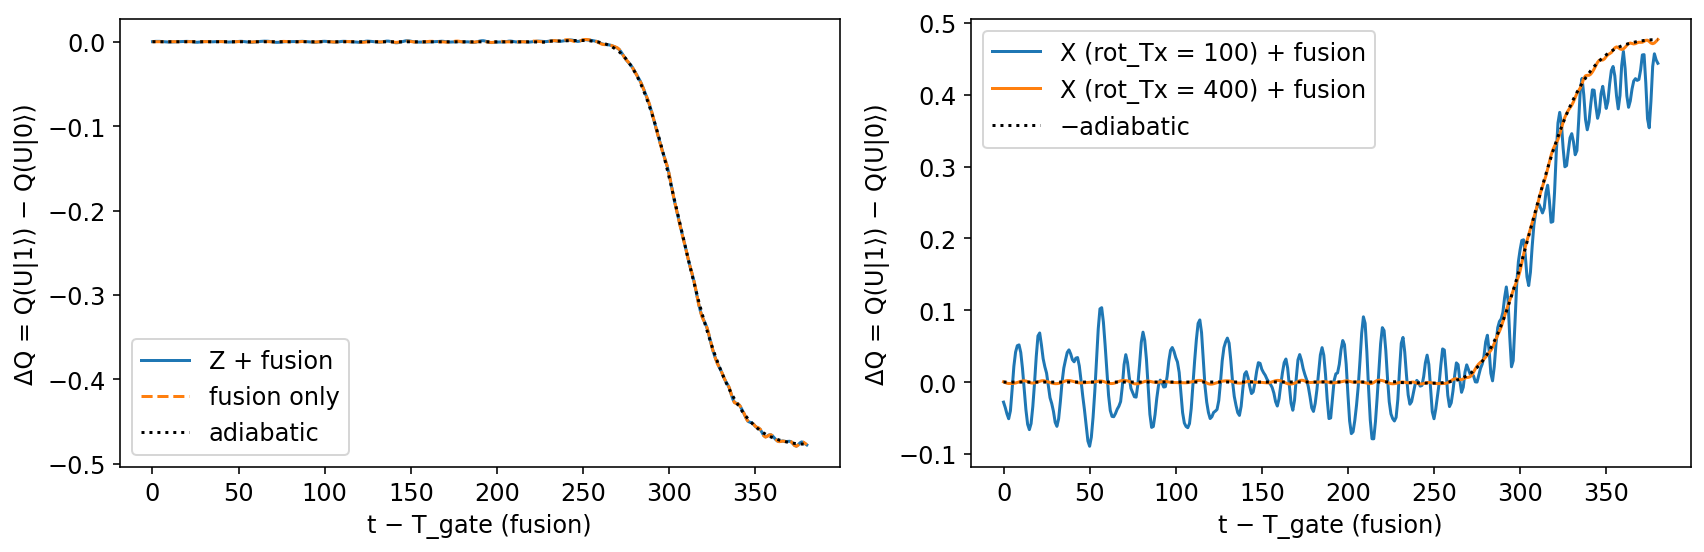

In [12]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(tsZ - tsZ[0], dQZ, label="Z + fusion")
ax[0].plot(tsF - tsF[0], dQF, "--", label="fusion only")
ax[0].plot(tsF - tsF[0], dQFad, "k:", label="adiabatic")
for rot, r in resX.items():
    ts, dq, _ = r["fusion"]
    ax[1].plot(ts - ts[0], dq, label=f"X (rot_Tx = {rot:.0f}) + fusion")
ax[1].plot(tsF - tsF[0], [-v for v in dQFad], "k:", label="−adiabatic")
for a in ax:
    a.set_xlabel("t − T_gate (fusion)"); a.set_ylabel("ΔQ = Q(U|1⟩) − Q(U|0⟩)"); a.legend()
plt.tight_layout()

## Charge density δn(x, t) = n₁ − n₀

From the snapshots of the Z and X runs above. With $\tau_z = (1, 1, -1, -1)$ per site,
$\delta n(\mathbf r, t) = \sum_{k=A,B}\sum_{\rm orb}\tau_z|\psi_k(\mathbf r, t)|^2$ is the density difference between logical
$|1\rangle = |11\rangle$ and $|0\rangle = |00\rangle$, and $\Delta Q = \sum_k\langle\psi_k|\tau_z|\psi_k\rangle$ its total. Left panel:
$\log_{10}|\delta n|$ along the horizontal chain over the full protocol (dashed lines: end of the first exchange and of
the gate); right panel: $\delta n$ during the fusion. Dotted lines mark the junctions.

Z: T_gate = 4080, 1197 snapshots, ΔQ(T) = -0.477719


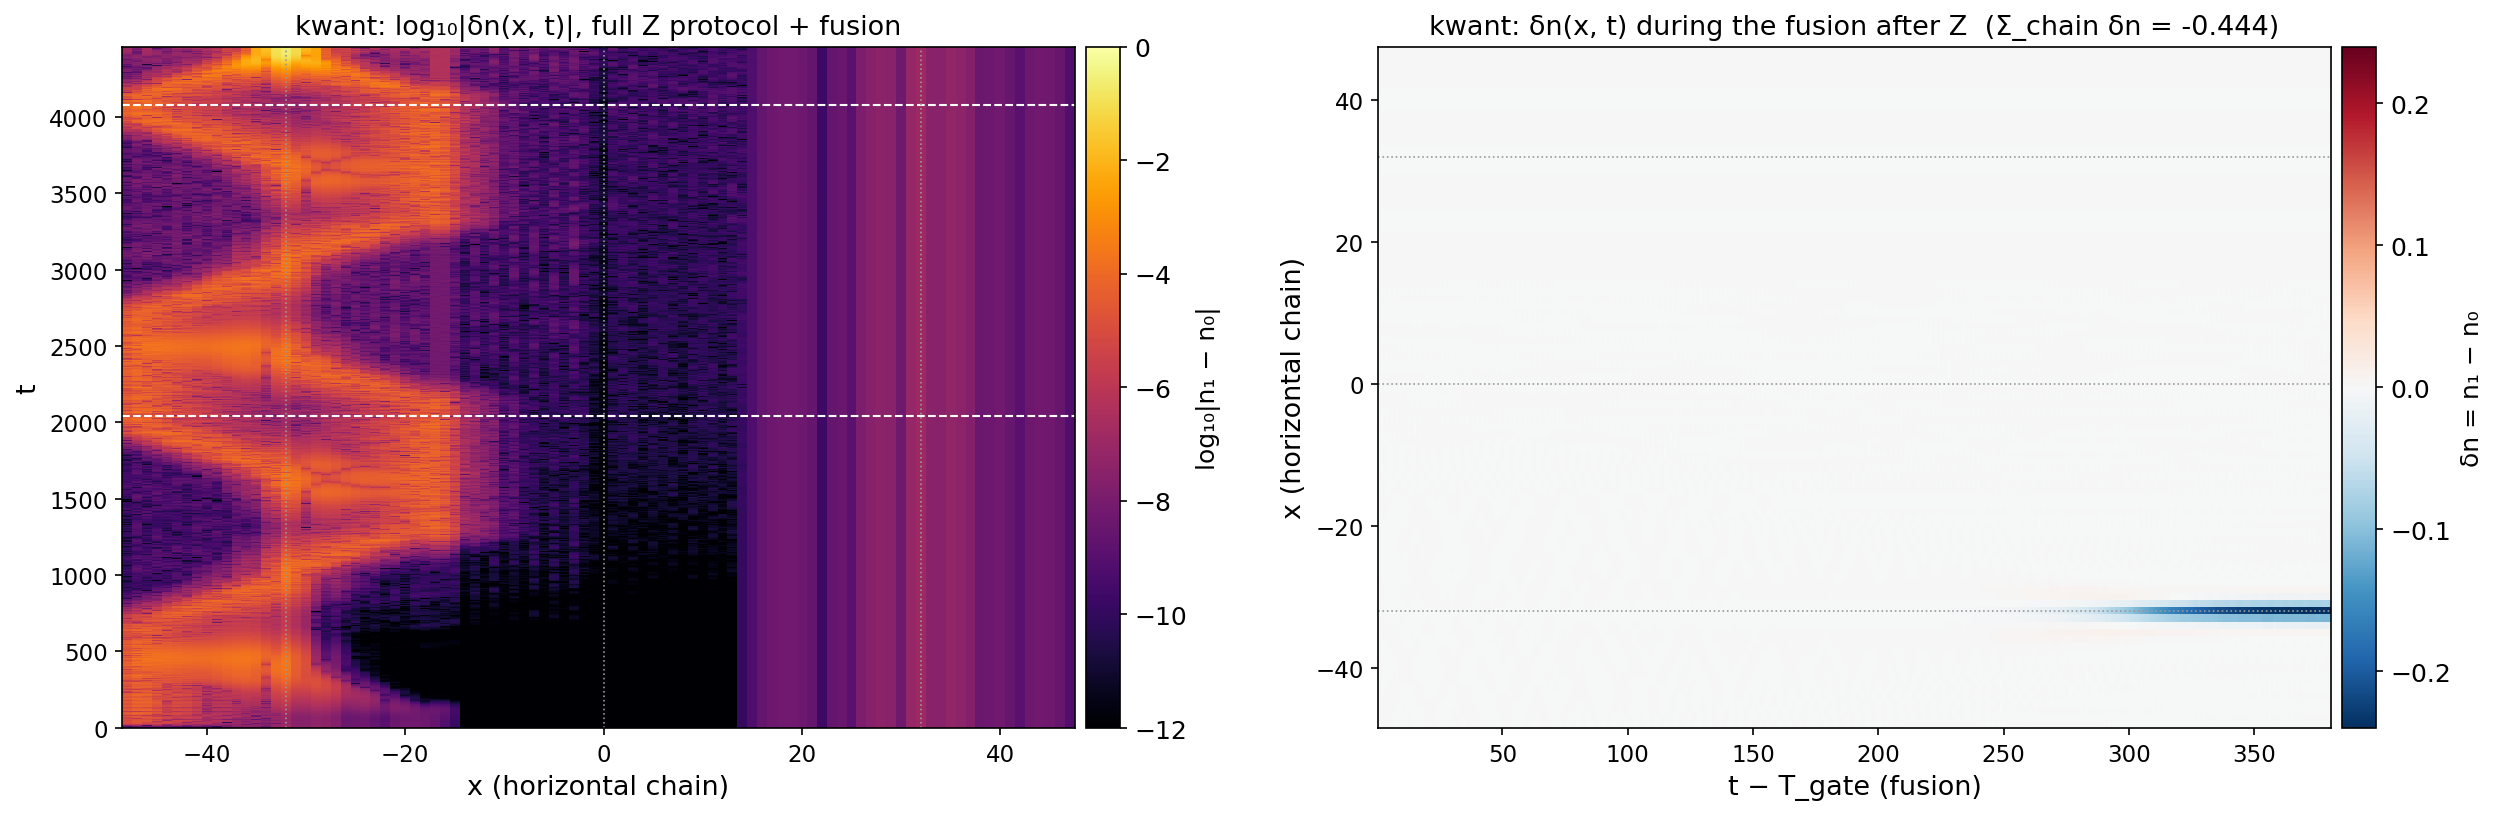

X (rot_Tx = 100): T_gate = 1940, 769 snapshots, ΔQ(T) = +0.443864


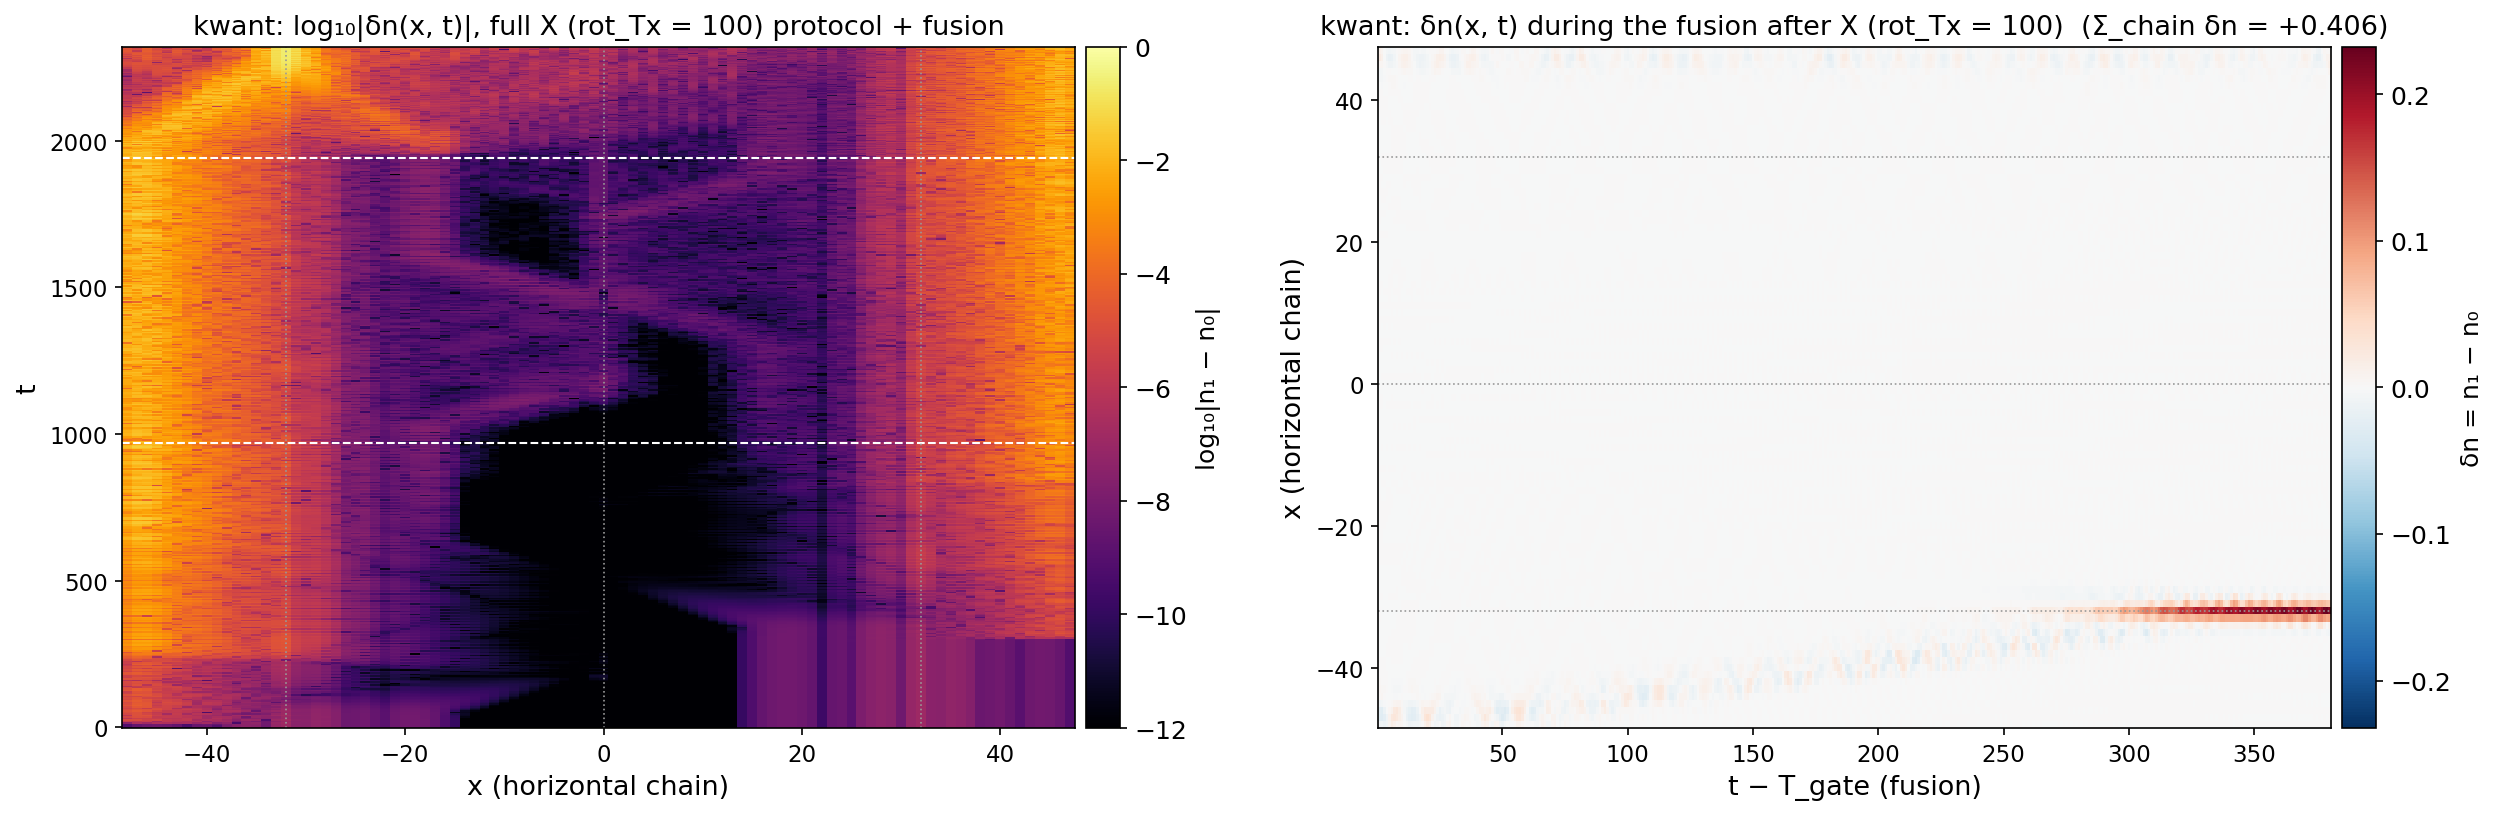

X (rot_Tx = 400): T_gate = 7760, 1933 snapshots, ΔQ(T) = +0.477005


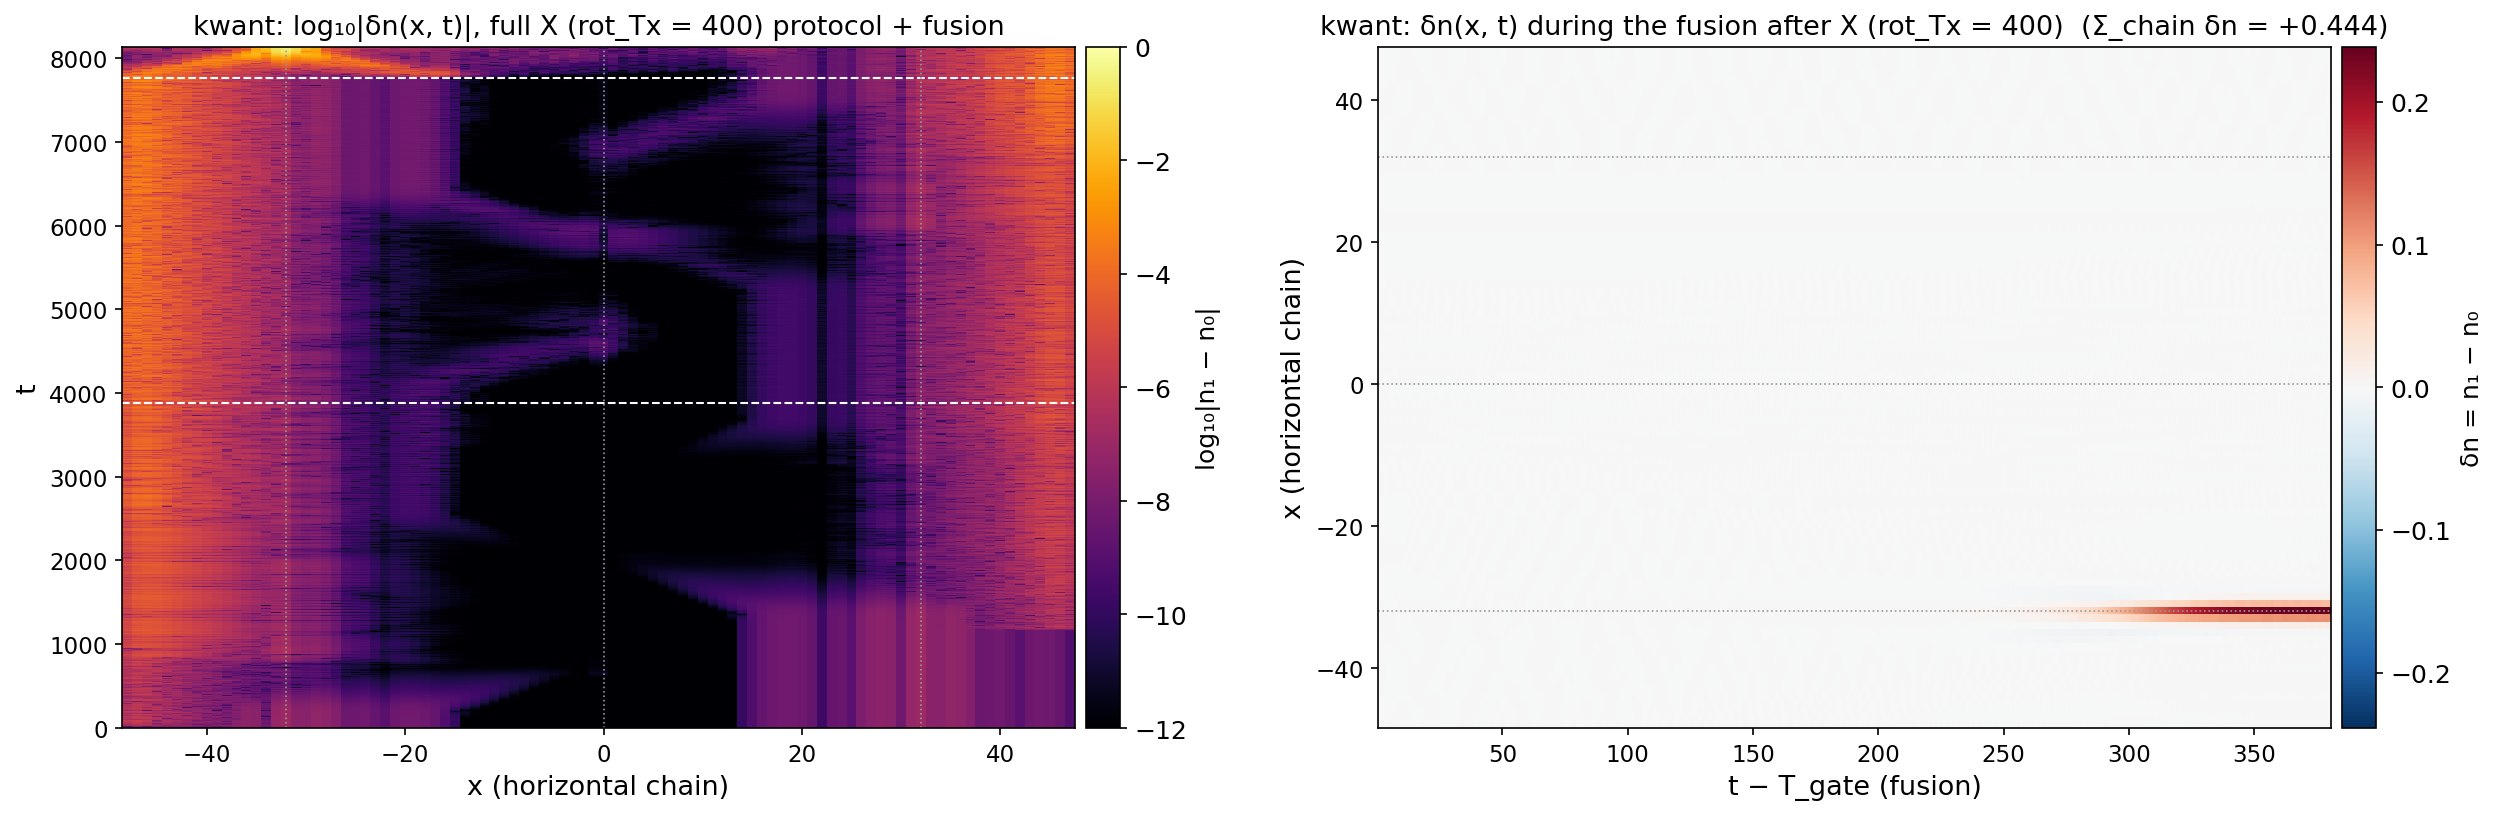

In [13]:
hz = np.where(ys == 0)[0]; hz = hz[np.argsort(xs[hz])]               # horizontal chain, left to right
dn_h = lambda V: (tauz[:, None] * np.abs(V) ** 2).sum(axis=1).reshape(N, 4).sum(axis=1)[hz]

def density_figure(ts, x, D, Tg, gate, method, out):
    fig, ax = plt.subplots(1, 2, figsize=(17.04, 5.6), dpi=150)
    L = np.log10(np.maximum(np.abs(D), 1e-16))
    im0 = ax[0].pcolormesh(x, ts, L, cmap="inferno", vmin=-12, vmax=0, shading="nearest", rasterized=True)
    for yl in (Tg / 2, Tg):
        ax[0].axhline(yl, color="white", ls="--", lw=1)
    ax[0].set(xlabel="x (horizontal chain)", ylabel="t", title=f"{method}: log₁₀|δn(x, t)|, full {gate} protocol + fusion")
    fig.colorbar(im0, ax=ax[0], pad=0.01, label="log₁₀|n₁ − n₀|")
    sel = ts >= Tg
    lim = np.abs(D[sel]).max()
    im1 = ax[1].pcolormesh(ts[sel] - Tg, x, D[sel].T, cmap="RdBu_r", vmin=-lim, vmax=lim, shading="nearest",
                           rasterized=True)
    ax[1].set(xlabel="t − T_gate (fusion)", ylabel="x (horizontal chain)",
              title=f"{method}: δn(x, t) during the fusion after {gate}  (Σ_chain δn = {D[-1].sum():+.3f})")
    fig.colorbar(im1, ax=ax[1], pad=0.01, label="δn = n₁ − n₀")
    for xc_ in (center_x(c) for c in range(1, NCELL + 1)):
        ax[0].axvline(xc_, color="0.6", lw=0.8, ls=":")
        ax[1].axhline(xc_, color="0.6", lw=0.8, ls=":")
    for a_ in ax:
        a_.title.set_size(13); a_.xaxis.label.set_size(13); a_.yaxis.label.set_size(13); a_.tick_params(labelsize=11)
    fig.tight_layout(); fig.savefig(out); plt.show(); plt.close(fig)

DN = {}
for key, gate, (ts, Vs, Tg) in [("Z", "Z", snapZ),
                                ("X100", "X (rot_Tx = 100)", resX[100.0]["snap"]),
                                ("X400", "X (rot_Tx = 400)", resX[400.0]["snap"])]:
    D = np.array([dn_h(V) for V in Vs])                               # (t, x)
    DN[key] = (ts, D, Tg)
    np.savez(os.path.join(DATA_DIR, f"gate_density_kwant_{key}.npz"), ts=ts, x=xs[hz], D=D, Tg=Tg)
    print(f"{gate}: T_gate = {Tg:.0f}, {len(ts)} snapshots, ΔQ(T) = {sum(dQ_modes(Vs[-1])):+.6f}")
    density_figure(ts, xs[hz], D, Tg, gate, "kwant", os.path.join(DATA_DIR, f"gate_density_kwant_{key}.png"))